# Notebook 2 — Entrenamiento y comparación de modelos

Entrenamos una **CNN custom** (Modelo A), la evaluamos junto a un modelo
preentrenado **InsightFace / ArcFace** (Modelo B) sobre el mismo conjunto de
test, y elegimos el mejor para integrar en la aplicación.

## Equipo
- Alumno 1 : **Alejandro Armas**
- Alumno 2 : **Gabriel Soda**

In [4]:
import os

# Necesario para GPU ROCm 6700xt
os.environ["HSA_OVERRIDE_GFX_VERSION"] = "10.3.0"
os.environ["ROCM_PATH"] = "/opt/rocm"

In [5]:
import sys
import time
from collections import Counter
from pathlib import Path

import altair as alt
import cv2
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
import torch.nn as nn
import torch.nn.functional as F
from insightface.app import FaceAnalysis
from IPython.display import display
from sklearn.metrics import (
    auc,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_curve,
    adjusted_rand_score,
    normalized_mutual_info_score,
    silhouette_score,
)
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder

disable_max_rows = getattr(alt.data_transformers, "disable_max_rows", None)
if callable(disable_max_rows):
    alt.data_transformers.disable_max_rows()

In [6]:
# --- Configuración ----------------------------------------------------------
DATA_DIR = Path("data/images")
OUTPUT_DIR = Path("output")
ALIGNED_DIR = OUTPUT_DIR / "aligned_112"
MODEL_DIR = Path("models") / "experimento_v2"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

FACE_SIZE = 112
DETECTION_THRESHOLD = 0.60
DETECTION_SIZE = (160, 160)

SEED = 42
BATCH_SIZE = 64
LEARNING_RATE = 1e-3
EMBEDDING_DIM = 128
EPOCHS = 100
PATIENCE = 7
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

torch.manual_seed(SEED)
np.random.seed(SEED)

print(f"Dispositivo: {DEVICE}")
if DEVICE.type == "cuda":
    print(f"  GPU: {torch.cuda.get_device_name(0)}")

Dispositivo: cuda
  GPU: NVIDIA GeForce RTX 3080 Ti


## Carga de splits y codificación de etiquetas

In [7]:
for split_name, csv_path in [
    ("train", OUTPUT_DIR / "train.csv"),
    ("val", OUTPUT_DIR / "val.csv"),
    ("test", OUTPUT_DIR / "test.csv"),
]:
    if not csv_path.exists():
        raise RuntimeError(f"No se encontró {csv_path}. Ejecutá primero la notebook 1.")

train_df = pl.read_csv(OUTPUT_DIR / "train.csv")
val_df = pl.read_csv(OUTPUT_DIR / "val.csv")
test_df = pl.read_csv(OUTPUT_DIR / "test.csv")

for split_name, df in [("train", train_df), ("val", val_df), ("test", test_df)]:
    assert df.height > 0, f"El conjunto {split_name} está vacío"
    assert df["path"].null_count() == 0
    assert df["identity"].null_count() == 0
    assert df["path"].n_unique() == df.height, f"Rutas duplicadas en {split_name}"
    print(
        f"{split_name}: {df.height} imágenes, {df['identity'].n_unique()} identidades"
    )

print(train_df.head())

train: 14000 imágenes, 100 identidades
val: 1500 imágenes, 100 identidades
test: 1500 imágenes, 100 identidades
shape: (5, 2)
┌─────────────────────────────────┬──────────────┐
│ path                            ┆ identity     │
│ ---                             ┆ ---          │
│ str                             ┆ str          │
╞═════════════════════════════════╪══════════════╡
│ train/Adriana Lima/Adriana Lim… ┆ Adriana Lima │
│ train/Adriana Lima/Adriana Lim… ┆ Adriana Lima │
│ train/Adriana Lima/Adriana Lim… ┆ Adriana Lima │
│ train/Adriana Lima/Adriana Lim… ┆ Adriana Lima │
│ train/Adriana Lima/Adriana Lim… ┆ Adriana Lima │
└─────────────────────────────────┴──────────────┘


In [8]:
label_encoder = LabelEncoder()
label_encoder.fit(sorted(train_df["identity"].unique().to_list()))
NUM_CLASSES = len(label_encoder.classes_)
assert set(val_df["identity"]) == set(label_encoder.classes_)
assert set(test_df["identity"]) == set(label_encoder.classes_)
print(f"Clases (identidades): {NUM_CLASSES}")


# Map identity → label en los 3 splits
def add_label(df):
    return df.with_columns(
        pl.Series(
            "label", label_encoder.transform(df["identity"].to_list()), dtype=pl.Int64
        )
    )


train_df = add_label(train_df)
val_df = add_label(val_df)
test_df = add_label(test_df)

Clases (identidades): 100


## Dataset / DataLoader de PyTorch

Leemos los recortes alineados 112×112 producidos por la notebook 1

In [9]:
class AlignedDataset(torch.utils.data.Dataset):
    def __init__(self, df, image_dir):
        self.df = df
        self.image_dir = image_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.row(idx, named=True)
        img_path = self.image_dir / row["path"]
        img_bgr = cv2.imread(str(img_path))
        if img_bgr is None:
            raise FileNotFoundError(f"No se pudo leer: {img_path}")
        if img_bgr.shape != (FACE_SIZE, FACE_SIZE, 3):
            raise ValueError(f"Tamaño inesperado en {img_path}: {img_bgr.shape}")

        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        img = torch.from_numpy(img_rgb).permute(2, 0, 1).float() / 255.0
        return img, int(row["label"])


train_ds = AlignedDataset(train_df, ALIGNED_DIR)
val_ds = AlignedDataset(val_df, ALIGNED_DIR)
test_ds = AlignedDataset(test_df, ALIGNED_DIR)

## Agrupación de imágenes con DataLoader

Cada lote contiene hasta 64 imágenes. Se mezcla solamente train, con un
generador de semilla fija. num_workers=0 carga en el proceso de la notebook.
La memoria fijada se habilita solo cuando se utiliza CUDA.

In [10]:
train_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
    generator=torch.Generator().manual_seed(SEED),
)
val_loader = torch.utils.data.DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)
test_loader = torch.utils.data.DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=DEVICE.type == "cuda",
)

print(
    f"Batches — train: {len(train_loader)} | val: {len(val_loader)} | test: {len(test_loader)}"
)

Batches — train: 219 | val: 24 | test: 24


## Visualización del lote y sus etiquetas

OpenCV lee BGR; el Dataset convierte a RGB, cambia de HWC a CHW y escala
a [0, 1]. Para Matplotlib volvemos a HWC. Se muestran hasta 16 imágenes,
que pueden ser originales o aumentadas guardadas.
Se usa un cargador separado para no avanzar el generador del entrenamiento.

Imágenes: torch.Size([64, 3, 112, 112]) torch.float32
Etiquetas: torch.Size([64]) torch.int64


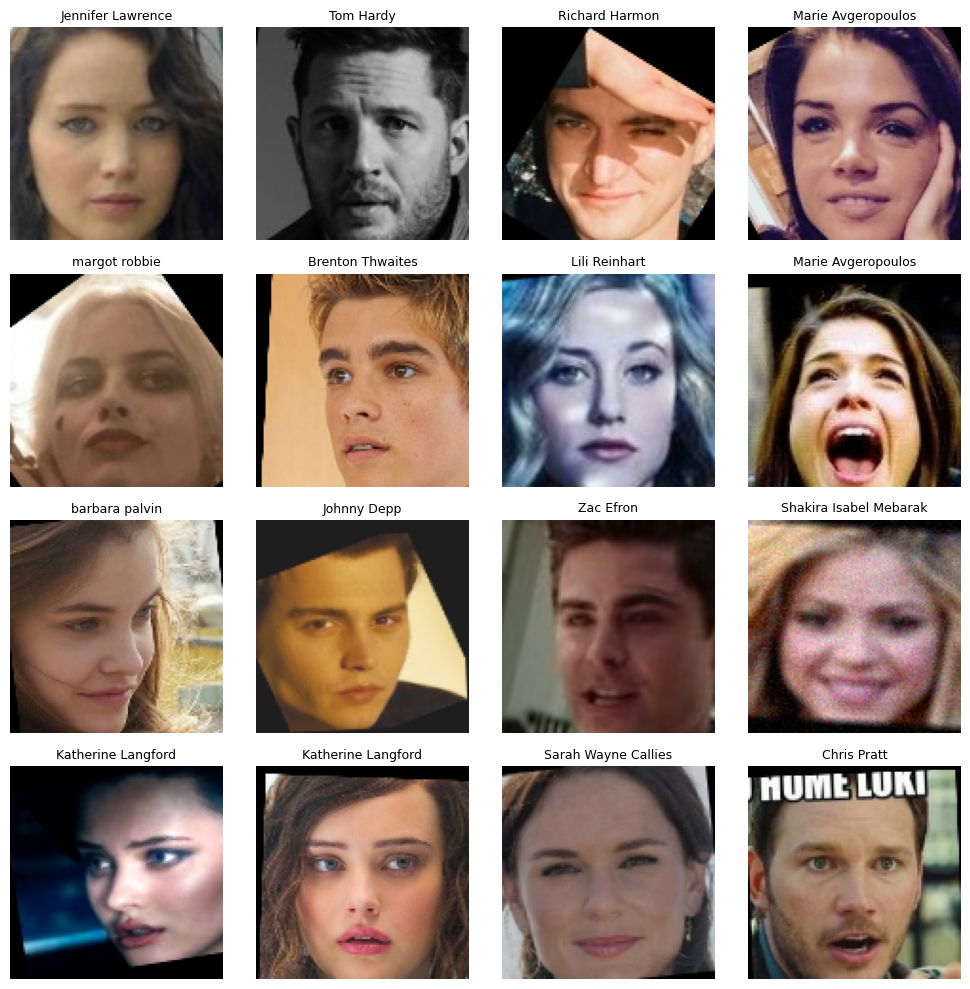

In [11]:
preview_loader = torch.utils.data.DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    generator=torch.Generator().manual_seed(SEED),
)
images, labels = next(iter(preview_loader))
assert images.shape == (min(BATCH_SIZE, len(train_ds)), 3, FACE_SIZE, FACE_SIZE)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64
assert 0 <= images.min() <= images.max() <= 1
assert 0 <= labels.min() <= labels.max() < NUM_CLASSES
print("Imágenes:", images.shape, images.dtype)
print("Etiquetas:", labels.shape, labels.dtype)

fig, axes = plt.subplots(4, 4, figsize=(10, 10))
for i, ax in enumerate(axes.flat):
    if i < len(images):
        ax.imshow(images[i].permute(1, 2, 0).numpy())
        ax.set_title(label_encoder.classes_[labels[i].item()], fontsize=9)
    ax.axis("off")
plt.tight_layout()
plt.show()

## 3.1 Modelo A — CNN Custom

### 3.1.1 Arquitectura

In [12]:
class ModelA(nn.Module):
    """CNN custom simple: 3 bloques conv + embedding + clasificador."""

    def __init__(self, num_classes: int) -> None:
        super().__init__()
        self.features = nn.Sequential(
            self._conv_block(3, 32),  # 56x56
            self._conv_block(32, 64),  # 28x28
            self._conv_block(64, 128),  # 14x14
        )
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.2)
        self.fc_embedding = nn.Linear(128, 128)
        self.bn_embedding = nn.BatchNorm1d(128)
        self.classifier = nn.Linear(128, num_classes)

    def _conv_block(self, in_ch: int, out_ch: int) -> nn.Sequential:
        return nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),
        )

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.features(x)
        x = self.pool(x).view(x.size(0), -1)
        x = self.dropout(x)
        emb = self.fc_embedding(x)
        emb = self.bn_embedding(emb)
        return self.classifier(emb), emb

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        return F.normalize(self.forward(x)[1], p=2, dim=1)


class ModelA2(nn.Module):
    """ResNet simplificado: stem + 3 bottleneck blocks."""

    def __init__(self, num_classes: int) -> None:
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
        )
        # layer1  (112x112)
        self.b1 = nn.Sequential(
            nn.Conv2d(32, 32, 1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, 3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 64, 1, bias=False),
            nn.BatchNorm2d(64),
        )
        self.s1 = nn.Sequential(nn.Conv2d(32, 64, 1, bias=False), nn.BatchNorm2d(64))
        # layer2  (112 -> 56)
        self.b2 = nn.Sequential(
            nn.Conv2d(64, 64, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 128, 1, bias=False),
            nn.BatchNorm2d(128),
        )
        self.s2 = nn.Sequential(
            nn.Conv2d(64, 128, 1, stride=2, bias=False), nn.BatchNorm2d(128)
        )
        # layer3  (56 -> 28)
        self.b3 = nn.Sequential(
            nn.Conv2d(128, 128, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 3, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, 1, bias=False),
            nn.BatchNorm2d(128),
        )
        self.s3 = nn.Sequential(
            nn.Conv2d(128, 128, 1, stride=2, bias=False), nn.BatchNorm2d(128)
        )
        self.relu = nn.ReLU(inplace=True)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(0.3)
        self.fc_embedding = nn.Linear(128, 128)
        self.bn_embedding = nn.BatchNorm1d(128)
        self.classifier = nn.Linear(128, num_classes)

    def forward(self, x: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
        x = self.stem(x)
        x = self.relu(self.b1(x) + self.s1(x))
        x = self.relu(self.b2(x) + self.s2(x))
        x = self.relu(self.b3(x) + self.s3(x))
        x = self.pool(x).view(x.size(0), -1)
        x = self.dropout(x)
        emb = self.fc_embedding(x)
        emb = self.bn_embedding(emb)
        return self.classifier(emb), emb

    def get_embedding(self, x: torch.Tensor) -> torch.Tensor:
        return F.normalize(self.forward(x)[1], p=2, dim=1)



# --- Instancia inicial (A) ---------------------------------------------------
model = ModelA(NUM_CLASSES).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Modelo base: A — CNN custom simple")
print(f"Parámetros entrenables: {n_trainable:,}")
print(f"Número de clases: {NUM_CLASSES}")

Modelo base: A — CNN custom simple
Parámetros entrenables: 123,140
Número de clases: 100


**Modelos Custom:**
Vamos a probar dos variantes:
- **A:** CNN custom con bloques conv simples (3×3 + BatchNorm + ReLU + MaxPool).
  Liviana y rápida.
- **A2:** ResNet con *bottlenecks* (1×1 → 3×3 → 1×1) + *skip connections*.
  Permite entrenar más profundo sin desvanecimiento de gradientes.

- **Global Average Pooling**, **Dropout**, **BatchNorm** en embedding y
  **L2-normalización** son comunes a ambas variantes.

### 3.1.2 Hiperparámetros y entrenamiento

El archivo `*_best.pth` conserva el modelo con mayor accuracy de validación.
El archivo `*_checkpoint.pt` guarda el estado de la última época completada,
incluso si la validación no mejoró: modelo, optimizador, scheduler e historial.
Al reanudar se continúa en la época siguiente salvo que ya se haya alcanzado el early stopping, en ese caso
no se agregan épocas. Una interrupción a mitad de época obliga a repetirla.
Si solo existe el mejor modelo, se recuperan sus pesos y se reinician el
optimizador y el historial. No se restaura la secuencia aleatoria exacta.

Usamos el optimizador Adam con valores típicos bien probados: learning rate inicial de 1e-3 y weight decay de 1e-4. El scheduler reduce el learning rate cuando la métrica de validación deja de mejorar.

In [13]:
def train_model(model, model_pth, ckpt_path, epochs=EPOCHS, patience=PATIENCE):
    """Guarda el mejor modelo y un checkpoint de cada época completada."""
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max", factor=0.5, patience=3
    )

    best_val_acc = float("-inf")
    patience_counter = 0
    history = []
    start_epoch = 1

    if ckpt_path.exists():
        ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        start_epoch = ckpt["epoch"] + 1
        best_val_acc = ckpt["best_val_acc"]
        patience_counter = ckpt["patience_counter"]
        history = ckpt["history"]
        print(
            f"Restaurado desde checkpoint: epoch {start_epoch - 1}, best_val_acc={best_val_acc:.4f}"
        )
    elif model_pth.exists():
        # Cargar pesos sin reemplazar el modelo asociado al optimizador.
        saved_model = torch.load(model_pth, map_location=DEVICE, weights_only=False)
        model.load_state_dict(saved_model.state_dict())
        del saved_model
        model.eval()
        val_loss = val_correct = val_total = 0.0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = (
                    imgs.to(DEVICE, non_blocking=True),
                    lbls.to(DEVICE, non_blocking=True),
                )
                logits, _ = model(imgs)
                loss = criterion(logits, lbls)
                val_loss += loss.item() * imgs.size(0)
                val_correct += (logits.argmax(dim=1) == lbls).sum().item()
                val_total += lbls.size(0)
        val_loss /= val_total
        val_acc = val_correct / val_total
        best_val_acc = val_acc
        print(
            f"Cargado .pth existente. Computado val_acc={best_val_acc:.4f} → best_val_acc"
        )

    if patience_counter >= patience:
        print("El checkpoint ya alcanzó early stopping, no se agregan épocas.")
        return best_val_acc, history

    print(f"Iniciando entrenamiento desde epoch {start_epoch}...")
    for epoch in range(start_epoch, epochs + 1):
        model.train()
        train_loss = train_correct = train_total = 0.0
        for imgs, lbls in train_loader:
            imgs, lbls = (
                imgs.to(DEVICE, non_blocking=True),
                lbls.to(DEVICE, non_blocking=True),
            )
            optimizer.zero_grad()
            logits, _ = model(imgs)
            loss = criterion(logits, lbls)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * imgs.size(0)
            train_correct += (logits.argmax(dim=1) == lbls).sum().item()
            train_total += lbls.size(0)
        train_loss /= train_total
        train_acc = train_correct / train_total

        model.eval()
        val_loss = val_correct = val_total = 0.0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = (
                    imgs.to(DEVICE, non_blocking=True),
                    lbls.to(DEVICE, non_blocking=True),
                )
                logits, _ = model(imgs)
                loss = criterion(logits, lbls)
                val_loss += loss.item() * imgs.size(0)
                val_correct += (logits.argmax(dim=1) == lbls).sum().item()
                val_total += lbls.size(0)
        val_loss /= val_total
        val_acc = val_correct / val_total

        history.append([epoch, train_loss, train_acc, val_loss, val_acc])
        scheduler.step(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0
            best_tmp = model_pth.with_suffix(model_pth.suffix + ".tmp")
            torch.save(model, best_tmp)
            best_tmp.replace(model_pth)
            print(
                f"Epoch {epoch:02d}  train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}  [MEJOR — guardado]"
            )
        else:
            patience_counter += 1
            print(
                f"Epoch {epoch:02d}  train_loss={train_loss:.4f} train_acc={train_acc:.4f} | "
                f"val_loss={val_loss:.4f} val_acc={val_acc:.4f}"
            )
        # Se guarda la última época incluso cuando no mejora la validación.
        checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_acc": best_val_acc,
            "patience_counter": patience_counter,
            "history": history,
        }
        # Reemplazar el checkpoint solo cuando termina de escribirse.
        checkpoint_tmp = ckpt_path.with_suffix(ckpt_path.suffix + ".tmp")
        torch.save(checkpoint, checkpoint_tmp)
        checkpoint_tmp.replace(ckpt_path)

        if patience_counter >= patience:
            print(f"Early stopping en epoch {epoch} ({patience} épocas sin mejora)")
            break

    print(f"\nMejor validation accuracy: {best_val_acc:.4f}")
    return best_val_acc, history


@torch.no_grad()
def extract_embeddings(data_loader, model, device):
    model.eval()
    embs, labs = [], []
    for imgs, lbls in data_loader:
        imgs = imgs.to(device, non_blocking=True)
        e = model.get_embedding(imgs)
        embs.append(e.cpu().numpy())
        labs.extend(lbls.numpy().tolist())
    return np.vstack(embs), np.array(labs)

In [14]:
results = {}

EXPERIMENTO A: FaceCNN 32→64→128 | emb=128
Iniciando entrenamiento desde epoch 1...
Epoch 01  train_loss=4.5080 train_acc=0.0326 | val_loss=4.3382 val_acc=0.0467  [MEJOR — guardado]
Epoch 02  train_loss=4.3208 train_acc=0.0499 | val_loss=4.2264 val_acc=0.0593  [MEJOR — guardado]
Epoch 03  train_loss=4.1744 train_acc=0.0673 | val_loss=4.1323 val_acc=0.0680  [MEJOR — guardado]
Epoch 04  train_loss=4.0382 train_acc=0.0791 | val_loss=4.3256 val_acc=0.0500
Epoch 05  train_loss=3.9305 train_acc=0.0919 | val_loss=3.8436 val_acc=0.1000  [MEJOR — guardado]
Epoch 06  train_loss=3.8084 train_acc=0.1054 | val_loss=3.7732 val_acc=0.1140  [MEJOR — guardado]
Epoch 07  train_loss=3.7166 train_acc=0.1194 | val_loss=3.6603 val_acc=0.1140
Epoch 08  train_loss=3.6029 train_acc=0.1406 | val_loss=4.5471 val_acc=0.0720
Epoch 09  train_loss=3.5131 train_acc=0.1490 | val_loss=3.5137 val_acc=0.1533  [MEJOR — guardado]
Epoch 10  train_loss=3.4019 train_acc=0.1667 | val_loss=3.6900 val_acc=0.1280
Epoch 11  train_

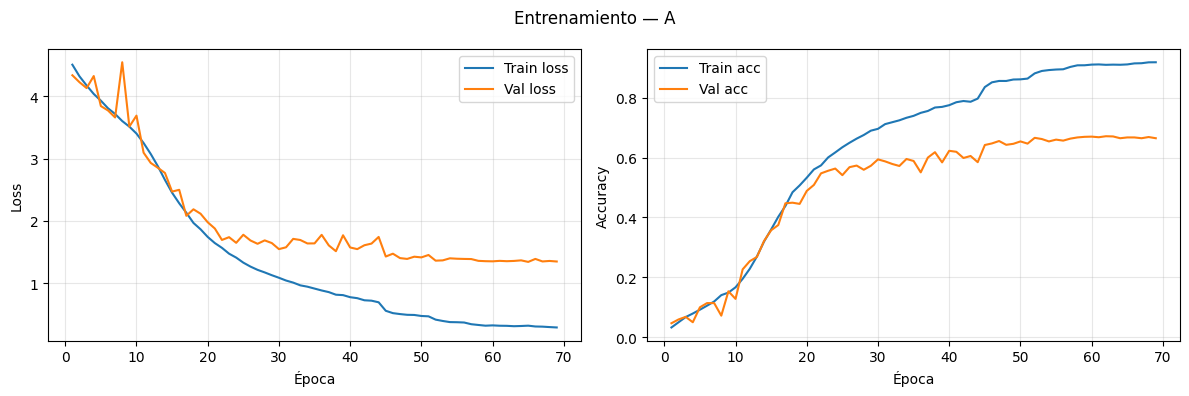

In [15]:
# Entrenar A
model = ModelA(NUM_CLASSES).to(DEVICE)

n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)

desc = "32→64→128 | emb=128"
suffix = "custom_cnn"

print(f"Modelo Custom A: {desc}")
print(f"Parámetros entrenables: {n_trainable:,}")

model_pth = MODEL_DIR / f"{suffix}_best.pth"
ckpt_path = MODEL_DIR / f"{suffix}_checkpoint.pt"

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
best_val_acc, history = train_model(model, model_pth, ckpt_path)

# Curvas
hist = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist[:, 0], hist[:, 1], label="Train loss")
axes[0].plot(hist[:, 0], hist[:, 3], label="Val loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(hist[:, 0], hist[:, 2], label="Train acc")
axes[1].plot(hist[:, 0], hist[:, 4], label="Val acc")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.suptitle("Entrenamiento — A")
plt.tight_layout()
plt.show()

# Tiempo inferencia
model = torch.load(model_pth, map_location=DEVICE, weights_only=False)
model.eval().to(DEVICE)
dummy = torch.randn(1, 3, FACE_SIZE, FACE_SIZE, device=DEVICE)
with torch.no_grad():
    for _ in range(5):
        _ = model.get_embedding(dummy)
    # Esperar a que termine el calentamiento antes de iniciar el reloj.
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    t0 = time.perf_counter()
    for _ in range(100):
        _ = model.get_embedding(dummy)
    # Esperar a que terminen las inferencias antes de detener el reloj.
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    t1 = time.perf_counter()
inf_ms = ((t1 - t0) / 100) * 1000

pth_size_mb = model_pth.stat().st_size / (1024 * 1024) if model_pth.exists() else 0.0

results["A"] = {
    "desc": desc,
    "best_val_acc": best_val_acc,
    "n_params": n_params,
    "inf_ms": inf_ms,
    "pth_size_mb": pth_size_mb,
    "model_pth": str(model_pth),
}

del model, dummy
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Observamos que el entrenamiento fue estable aunque se evidencian signos de sobreajuste. Sin embargo obtuvo un accuracy de 0.67 sobre el conjunto de validación, teniendo en cuenta lo simple de la arquitectura lo consideramos un resultado aceptable.

EXPERIMENTO A2: FaceResNet Bottleneck (1,1,1) | emb=128
Iniciando entrenamiento desde epoch 1...
Epoch 01  train_loss=4.4988 train_acc=0.0327 | val_loss=4.3796 val_acc=0.0473  [MEJOR — guardado]
Epoch 02  train_loss=4.3212 train_acc=0.0499 | val_loss=4.2725 val_acc=0.0500  [MEJOR — guardado]
Epoch 03  train_loss=4.1735 train_acc=0.0643 | val_loss=4.2788 val_acc=0.0540  [MEJOR — guardado]
Epoch 04  train_loss=4.0014 train_acc=0.0786 | val_loss=3.8891 val_acc=0.0847  [MEJOR — guardado]
Epoch 05  train_loss=3.8531 train_acc=0.0927 | val_loss=3.8063 val_acc=0.0933  [MEJOR — guardado]
Epoch 06  train_loss=3.7385 train_acc=0.1093 | val_loss=3.5870 val_acc=0.1153  [MEJOR — guardado]
Epoch 07  train_loss=3.6327 train_acc=0.1221 | val_loss=3.8668 val_acc=0.0960
Epoch 08  train_loss=3.5412 train_acc=0.1337 | val_loss=3.8928 val_acc=0.1053
Epoch 09  train_loss=3.4543 train_acc=0.1456 | val_loss=3.8577 val_acc=0.0960
Epoch 10  train_loss=3.3618 train_acc=0.1652 | val_loss=3.3948 val_acc=0.1720  [M

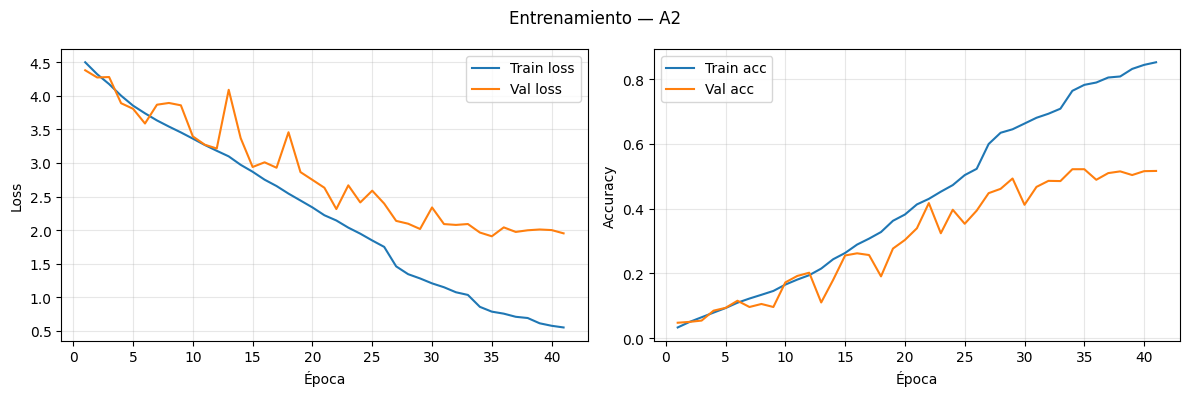

In [16]:
# Entrenar A2
model = ModelA2(NUM_CLASSES).to(DEVICE)
n_params = sum(p.numel() for p in model.parameters())
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
desc = "Bloques residuales 32→64→128 | emb=128"
suffix = "custom_cnn_A2"

print(f"Modelo Custom A2: {desc}")
print(f"Parámetros entrenables: {n_trainable:,}")

model_pth = MODEL_DIR / f"{suffix}_best.pth"
ckpt_path = MODEL_DIR / f"{suffix}_checkpoint.pt"

n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
best_val_acc, history = train_model(model, model_pth, ckpt_path)

# Curvas
hist = np.array(history)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(hist[:, 0], hist[:, 1], label="Train loss")
axes[0].plot(hist[:, 0], hist[:, 3], label="Val loss")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].plot(hist[:, 0], hist[:, 2], label="Train acc")
axes[1].plot(hist[:, 0], hist[:, 4], label="Val acc")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.suptitle("Entrenamiento — A2")
plt.tight_layout()
plt.show()

# Tiempo inferencia
model = torch.load(model_pth, map_location=DEVICE, weights_only=False)
model.eval().to(DEVICE)
dummy = torch.randn(1, 3, FACE_SIZE, FACE_SIZE, device=DEVICE)
with torch.no_grad():
    for _ in range(5):
        _ = model.get_embedding(dummy)
    # Esperar a que termine el calentamiento antes de iniciar el reloj.
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    t0 = time.perf_counter()
    for _ in range(100):
        _ = model.get_embedding(dummy)
    # Esperar a que terminen las inferencias antes de detener el reloj.
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    t1 = time.perf_counter()
inf_ms = ((t1 - t0) / 100) * 1000

pth_size_mb = model_pth.stat().st_size / (1024 * 1024) if model_pth.exists() else 0.0

results["A2"] = {
    "desc": desc,
    "best_val_acc": best_val_acc,
    "n_params": n_params,
    "inf_ms": inf_ms,
    "pth_size_mb": pth_size_mb,
    "model_pth": str(model_pth),
}

del model, dummy
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Observamos que A2 tuvo un sobreajuste aun más marcado que A, produciendo que el entrenamiento termine más temprano debido al early stopping. Reforzamos la idea de que una arquitectura tan chica no es suficiente para reconocer caras, por lo que la red aprende a memorizar los ejemplos de entrenamiento en lugar de generalizar.

### Comparación de los experimentos ejecutados

La tabla se construye con los resultados de A y A2. Se selecciona el
mejor modelo según accuracy de validación, sin utilizar el test para elegirlo.
El tiempo corresponde a la media de 100 inferencias con lote de una imagen
sintética, después de 5 de calentamiento, en el dispositivo indicado.
Incluye get_embedding; no incluye lectura, detección, alineación ni transferencia
desde CPU. La medición en GPU no sustituye la evaluación de costo en CPU.

| CNN | Mejor validación v1 | Mejor validación v2 | Diferencia | Mejor época v2 |
| --- | ---: | ---: | ---: | ---: |
| A | 52,20 % | 67,13 % | +14,93 pp | 62 |
| A2 | 33,47 % | 52,20 % | +18,73 pp | 34 |

V2 incorporó weight decay y separó el embedding normalizado del forward de clasificación. A2 también cambió a bloques residuales bottleneck. La comparación mide el efecto conjunto de los cambios. A y A2 terminaron en las épocas 69 y 41. En la mejor época de cada modelo, la accuracy de train fue 90,99 % y 76,44 %, respectivamente. La brecha con validación indica sobreajuste en ambos. A fue la CNN elegida para el análisis detallado.


In [17]:
summary_train = pl.DataFrame(
    {
        "exp": list(results.keys()),
        "arquitectura": [results[k]["desc"] for k in results],
        "val_acc": [round(results[k]["best_val_acc"], 4) for k in results],
        "params_M": [round(results[k]["n_params"] / 1e6, 2) for k in results],
        "dispositivo": [str(DEVICE) for k in results],
        "inf_ms": [round(results[k]["inf_ms"], 2) for k in results],
        "MB": [round(results[k]["pth_size_mb"], 2) for k in results],
    }
)
display(summary_train)

# Elegimos el mejor custom según val_acc para el análisis detallado posterior
best_exp = max(results, key=lambda k: results[k]["best_val_acc"])
print(
    f"\n>>> Mejor modelo custom: {best_exp} — val_acc={results[best_exp]['best_val_acc']:.4f}"
)

# Cargamos el mejor custom para seguir con la notebook como antes
MODEL_PTH = Path(results[best_exp]["model_pth"])
model = torch.load(MODEL_PTH, map_location=DEVICE, weights_only=False)
model.eval().to(DEVICE)

train_embs, train_labs = extract_embeddings(train_loader, model, DEVICE)
val_embs, val_labs = extract_embeddings(val_loader, model, DEVICE)
test_embs, test_labs = extract_embeddings(test_loader, model, DEVICE)
print(f"\nEmbeddings cargados del ganador ({best_exp}) — test: {test_embs.shape}")
print(f"Norma L2 promedio (test): {np.linalg.norm(test_embs, axis=1).mean():.4f}")


RESUMEN PARCIAL (entrenamiento)


exp,arquitectura,val_acc,params_M,dispositivo,inf_ms,MB
str,str,f64,f64,str,f64,f64
"""A""","""FaceCNN 32→64→128 | emb=128""",0.6713,0.12,"""cuda""",1.16,0.49
"""A2""","""FaceResNet Bottleneck (1,1,1) …",0.522,0.3,"""cuda""",4.06,1.2



>>> Mejor modelo custom: A — val_acc=0.6713

Embeddings cargados del ganador (A) — test: (1500, 128)
Norma L2 promedio (test): 1.0000


## 3.2 Modelo B — InsightFace / ArcFace (preentrenado)

Usamos el reconocedor de InsightFace (`buffalo_l`) como extractor puro.
No reentrenamos: solo extraemos embeddings del mismo split de test.
- **Arquitectura:** ResNet-50 entrenado con ArcFace.
- **Datos de entrenamiento:** millones de rostros públicos (MS1M / WebFace).
- **Dimensión del embedding:** 512.
- **Licencia:** uso no comercial / investigación (InsightFace).

In [ ]:
face_analysis = FaceAnalysis(name="buffalo_l", allowed_modules=["detection","recognition"])
face_analysis.prepare(ctx_id=0)
recognition_model = face_analysis.models["recognition"]

insight_test_embs = []
insight_test_labs = []
insight_val_embs = []
insight_val_labs = []

for images, labels in test_loader:
    # AlignedDataset entrega RGB en [0, 1]; ArcFace recibe imágenes BGR uint8.
    images_bgr = (images.permute(0, 2, 3, 1).numpy() * 255).round().astype(np.uint8)
    images_bgr = images_bgr[..., ::-1]

    for img_bgr, label in zip(images_bgr, labels.numpy()):
        embedding = recognition_model.get_feat(img_bgr)
        insight_test_embs.append(np.asarray(embedding).reshape(-1))
        insight_test_labs.append(label.item())

for images, labels in val_loader:
    # AlignedDataset entrega RGB en [0, 1]; ArcFace recibe imágenes BGR uint8.
    images_bgr = (images.permute(0, 2, 3, 1).numpy() * 255).round().astype(np.uint8)
    images_bgr = images_bgr[..., ::-1]

    for img_bgr, label in zip(images_bgr, labels.numpy()):
        embedding = recognition_model.get_feat(img_bgr)
        insight_val_embs.append(np.asarray(embedding).reshape(-1))
        insight_val_labs.append(label.item())

insight_test_embs = np.vstack(insight_test_embs)
insight_test_embs /= np.linalg.norm(insight_test_embs, axis=1, keepdims=True)
insight_test_labs = np.array(insight_test_labs)

insight_val_embs = np.vstack(insight_val_embs)
insight_val_embs /= np.linalg.norm(insight_val_embs, axis=1, keepdims=True)
insight_val_labs = np.array(insight_val_labs)

print(f"InsightFace test embeddings: {insight_test_embs.shape}")
print(f"Norma L2 promedio: {np.linalg.norm(insight_test_embs, axis=1).mean():.4f}")

print(f"InsightFace val embeddings: {insight_val_embs.shape}")
print(f"Norma L2 promedio: {np.linalg.norm(insight_val_embs, axis=1).mean():.4f}")

                                                                                                                                    
# --- Métricas de costo para InsightFace (usadas en sección 3.3 f) ---                                                               
# Tiempo de inferencia                                                                                                               
dummy_bgr = np.random.randint(0, 255, (FACE_SIZE, FACE_SIZE, 3), dtype=np.uint8)                                                     
for _ in range(5):                                                                                                                   
    _ = recognition_model.get_feat(dummy_bgr)                                                                                        
t0 = time.perf_counter()                                                                                                             
for _ in range(100):                                                                                                                 
    _ = recognition_model.get_feat(dummy_bgr)                                                                                        
t1 = time.perf_counter()                                                                                                             
insight_inf_ms = ((t1 - t0) / 100) * 1000                                                                                            
print(f"Tiempo medio inferencia InsightFace: {insight_inf_ms:.2f} ms/rostro")                                                        
                                                                                                                                    
# Ruta y tamaño del modelo .onnx                                                                                                     
insight_model_dir = Path.home() / ".insightface" / "models" / "buffalo_l"                                                            
insight_rec_path = insight_model_dir / "w600k_r50.onnx"                                                                              
insight_size_mb = (                                                                                                                  
    insight_rec_path.stat().st_size / (1024 * 1024) if insight_rec_path.exists() else 0.0                                            
)                                                                                                                                    
print(f"Modelo de reconocimiento: {insight_rec_path} ({insight_size_mb:.1f} MB)")    

## 3.3 Evaluación

Train, validación y test comparten las mismas 100 identidades, con fotos asignadas a splits distintos. Train contiene 7.000 recortes originales y 7.000 augmented. Validación y test contienen 1.500 recortes cada uno. La auditoría SHA-256 de los 17.000 archivos alineados no encontró hashes compartidos entre splits.

En verificación, ambos modelos se comparan con los mismos pares de fotos. Se fija un umbral por modelo con 600 pares positivos y 600 negativos de validación, cerca del punto de igual error (EER). Las decisiones con umbral en test usan ese valor. La ROC de test se calcula barriendo los puntajes.

Para la identificación cuantitativa, con semilla 42 se reserva una foto de test para registrar a cada una de 80 personas en la galería. Las fotos restantes de esas personas se usan como consultas conocidas. Todas las fotos de las otras 20 personas se usan como consultas fuera de galería. La demo visual usa una galería de 10 personas con tres fotos por persona.

Las 20 personas fuera de la galería también estuvieron en el entrenamiento de la CNN. Para evaluar la generalización a personas nunca vistas por la CNN queda pendiente un test separado con las identidades propuestas Lionel Messi, Cristiano Ronaldo y Mark Zuckerberg.

In [ ]:
def build_pairs(embeddings, labels, n_pos=800, n_neg=800, rng_seed=42):
    rng = np.random.default_rng(rng_seed)
    unique = np.unique(labels)
    pos_pairs = []
    for lab in unique:
        idxs = np.where(labels == lab)[0]
        if len(idxs) >= 2:
            # combinaciones simples; limitamos a n_pos para rapidez
            for i in range(min(len(idxs) - 1, max(1, n_pos // len(unique) + 1))):
                pos_pairs.append((idxs[i], idxs[i + 1]))
    rng.shuffle(pos_pairs)
    pos_pairs = pos_pairs[:n_pos]

    neg_pairs = []
    for _ in range(n_neg):
        l1, l2 = rng.choice(unique, 2, replace=False)
        i = rng.choice(np.where(labels == l1)[0])
        j = rng.choice(np.where(labels == l2)[0])
        neg_pairs.append((i, j))

    sims_pos = [float(np.dot(embeddings[i], embeddings[j])) for i, j in pos_pairs]
    sims_neg = [float(np.dot(embeddings[i], embeddings[j])) for i, j in neg_pairs]
    return sims_pos, sims_neg, pos_pairs, neg_pairs



def evaluate_verification(sims_pos, sims_neg):
    y_true = [1] * len(sims_pos) + [0] * len(sims_neg)
    y_scores = sims_pos + sims_neg
    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
    roc_auc = auc(fpr, tpr)
    fnr = 1 - tpr
    eer_idx = np.nanargmin(np.abs(fpr - fnr))
    eer = float(fpr[eer_idx])
    eer_thr = float(thresholds[eer_idx])
    # TAR @ FAR objetivo
    def tar_at_far(target_far):
        idx = np.searchsorted(fpr, target_far, side="right") - 1
        idx = max(0, idx)
        return float(tpr[idx])
    return {"auc": roc_auc, "eer": eer, "eer_thr": eer_thr,
            "tar_far_1e-2": tar_at_far(1e-2), "tar_far_1e-3": tar_at_far(1e-3),
            "fpr": fpr, "tpr": tpr, "thresholds": thresholds}


def evaluate_identification(embs, labels, unknown_frac=0.20, seed=42, thr=None):
    rng = np.random.default_rng(seed)
    unique = np.unique(labels)
    rng.shuffle(unique)
    n_unknown = max(1, int(len(unique) * unknown_frac))
    gallery_ids = unique[n_unknown:]
    unknown_ids = unique[:n_unknown]

    gal_embs, gal_labs = [], []
    qry_embs, qry_labs, qry_is_known = [], [], []
    for lab in gallery_ids:
        idxs = np.where(labels == lab)[0]
        rng.shuffle(idxs)
        gal_embs.append(embs[idxs[0]])
        gal_labs.append(lab)
        for q in idxs[1:]:
            qry_embs.append(embs[q]); qry_labs.append(lab); qry_is_known.append(True)
    for lab in unknown_ids:
        idxs = np.where(labels == lab)[0]
        for q in idxs:
            qry_embs.append(embs[q]); qry_labs.append(lab); qry_is_known.append(False)

    gal_arr = np.array(gal_embs)
    gal_labs_arr = np.array(gal_labs)
    qry_arr = np.array(qry_embs)
    qry_labs_arr = np.array(qry_labs)
    known_mask = np.array(qry_is_known)

    sims = qry_arr @ gal_arr.T
    best_sim = sims.max(axis=1)
    pred_idx = sims.argmax(axis=1)
    pred_labels = gal_labs_arr[pred_idx]

    # Si hay threshold, marcamos como "unknown" (-1) cuando best_sim < thr
    if thr is not None:
        pred_labels = np.where(best_sim < thr, -1, pred_labels)

    # Rank-1 / Top-5  (sobre known only, para no sesgar con unknowns)
    top1_known = float((pred_labels[known_mask] == qry_labs_arr[known_mask]).mean())
    # Top-5
    top5_idx = np.argpartition(-sims, min(5, sims.shape[1] - 1), axis=1)[:, :5]
    top5_correct = np.array([
        qry_labs_arr[i] in gal_labs_arr[top5_idx[i]] for i in range(len(qry_labs_arr))
    ])
    top5_known = float(top5_correct[known_mask].mean())

    # Métricas macro sobre todas las consultas de identidades registradas.
    # Un rechazo como unknown cuenta como falso negativo de la identidad real.
    y_true = qry_labs_arr[known_mask]
    y_pred = pred_labels[known_mask]
    prec = precision_score(
        y_true, y_pred, labels=gal_labs_arr, average="macro", zero_division=0
    )
    rec = recall_score(
        y_true, y_pred, labels=gal_labs_arr, average="macro", zero_division=0
    )
    f1 = f1_score(
        y_true, y_pred, labels=gal_labs_arr, average="macro", zero_division=0
    )

    # Unknown rejection rate: cuántos unknowns tienen best_sim por debajo del threshold
    unknown_mask = ~known_mask
    unknown_rejection_rate = 0.0
    if thr is not None and unknown_mask.sum() > 0:
        unknown_rejection_rate = float((best_sim[unknown_mask] < thr).mean())

    # False acceptance among unknowns (unknowns que pasan el umbral)
    unknown_fa_rate = 0.0
    if thr is not None and unknown_mask.sum() > 0:
        unknown_fa_rate = float((best_sim[unknown_mask] >= thr).mean())

    return {
        "top1_acc": top1_known,
        "top5_acc": top5_known,
        "precision_macro": prec,
        "recall_macro": rec,
        "f1_macro": f1,
        "n_gallery": len(gal_arr),
        "n_queries": len(qry_arr),
        "n_known_queries": int(known_mask.sum()),
        "n_unknown_queries": int(unknown_mask.sum()),
        "best_sims": best_sim,
        "query_labels": qry_labs_arr,
        "pred_labels": pred_labels,
        "known_mask": known_mask,
        "unknown_rejection_rate": unknown_rejection_rate,
        "unknown_fa_rate": unknown_fa_rate,
    }

### a) Verificación

In [ ]:
eval_results = {}
test_scores = {}
for name, embs, labs in [("CNN custom", test_embs, test_labs),
                          ("InsightFace", insight_test_embs, insight_test_labs)]:
    sp, sn, _, _ = build_pairs(embs, labs)
    test_scores[name] = sp, sn
    res = evaluate_verification(sp, sn)
    eval_results[name] = {"verification": res}
    print(f"\n{name}:")
    print(f"  AUC       = {res['auc']:.4f}")
    print(f"  EER       = {res['eer']:.4f}")
    print(f"  TAR@FAR=1e-2 = {res['tar_far_1e-2']:.4f}")
    print(f"  TAR@FAR=1e-3 = {res['tar_far_1e-3']:.4f}")

# Histogramas lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, (sp, sn)) in zip(axes, test_scores.items()):
    ax.hist(sp, bins=30, alpha=0.7, label="Misma persona", color="green", edgecolor="darkgreen")
    ax.hist(sn, bins=30, alpha=0.7, label="Distinta persona", color="red", edgecolor="darkred")
    ax.set_xlabel("Similitud coseno")
    ax.set_ylabel("Frecuencia")
    ax.set_title(name)
    ax.legend(); ax.grid(alpha=0.2)
plt.suptitle("Distribución de similitudes — verificación", fontsize=13)
plt.tight_layout(); plt.show()

# Curvas ROC lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (name, result) in zip(axes, eval_results.items()):
    res = result["verification"]
    ax.plot(res["fpr"], res["tpr"], lw=2, label=f"AUC={res['auc']:.3f}")
    ax.plot([0, 1], [0, 1], "k--", alpha=0.3)
    ax.scatter([res["eer"]], [1 - res["eer"]], color="red", zorder=5, label=f"EER={res['eer']:.3f}")
    ax.set_xlabel("FPR"); ax.set_ylabel("TPR")
    ax.set_title(name); ax.legend(); ax.grid(alpha=0.2)
plt.suptitle("Curvas ROC", fontsize=13)
plt.tight_layout(); plt.show()

### b) Identificación simple con galería visual

- 10 identidades "known" del test (3 imágenes registradas cada una).
- 5 queries known: nuevas imágenes de 5 de esas identidades.
- 5 queries unknown: imágenes de identidades no registradas.
- Usamos el umbral EER (calculado sobre val) para decidir "unknown".

In [ ]:
def simple_identification_demo(embs, labs, ds, name, thr, seed=42):
    rng = np.random.default_rng(seed)
    unique = np.unique(labs)
    rng.shuffle(unique)

    known_ids = unique[:10]
    unknown_pool = unique[10:]

    gallery_indices = []
    gallery_labels = []

    # 3 imágenes por known id para la galería
    for lab in known_ids:
        idxs = np.where(labs == lab)[0]
        if len(idxs) < 4:
            continue
        rng.shuffle(idxs)
        gallery_indices.extend(idxs[:3].tolist())
        gallery_labels.extend([lab] * 3)

    # 5 queries known (1 imagen extra de 5 ids known)
    known_query_indices = []
    known_query_labels = []
    for lab in known_ids[:5]:
        idxs = np.where(labs == lab)[0]
        used = {i for i, g in zip(gallery_indices, gallery_labels) if g == lab}
        remaining = [i for i in idxs if i not in used]
        if remaining:
            known_query_indices.append(remaining[0])
            known_query_labels.append(lab)

    # 5 queries unknown (1 imagen de 5 ids del unknown_pool)
    unknown_query_indices = []
    unknown_query_labels = []
    for lab in unknown_pool[:5]:
        idxs = np.where(labs == lab)[0]
        if len(idxs) > 0:
            unknown_query_indices.append(idxs[0])
            unknown_query_labels.append(lab)

    # Promediar embeddings por identidad en la galería
    gallery_emb_per_id = []
    gallery_id_per_emb = []
    for lab in known_ids:
        gal_idx = [i for i, g in enumerate(gallery_labels) if g == lab]
        if not gal_idx:
            continue
        embs_gal = embs[[gallery_indices[i] for i in gal_idx]]
        avg_emb = embs_gal.mean(axis=0)
        avg_emb = avg_emb / np.linalg.norm(avg_emb)
        gallery_emb_per_id.append(avg_emb)
        gallery_id_per_emb.append(lab)
    gallery_emb_arr = np.array(gallery_emb_per_id)
    gallery_id_arr = np.array(gallery_id_per_emb)

    # Queries
    all_q_idx = known_query_indices + unknown_query_indices
    all_q_labels = known_query_labels + unknown_query_labels
    all_q_is_known = [True] * len(known_query_indices) + [False] * len(unknown_query_indices)

    q_embs = embs[all_q_idx]
    sims = q_embs @ gallery_emb_arr.T
    best_sim = sims.max(axis=1)
    pred_idx = sims.argmax(axis=1)
    pred_labels = gallery_id_arr[pred_idx]
    pred_names = [label_encoder.classes_[l] for l in pred_labels]

    # Aplicar umbral: por debajo → unknown
    for i in range(len(best_sim)):
        if best_sim[i] < thr:
            pred_labels[i] = -1
            pred_names[i] = "unknown"

    # --- Visualizar galería (10 x 3) ---
    fig, axes = plt.subplots(10, 3, figsize=(9, 24))
    for row, lab in enumerate(known_ids):
        gal_idx_row = [i for i, g in enumerate(gallery_labels) if g == lab]
        for col, gi in enumerate(gal_idx_row[:3]):
            ax = axes[row, col]
            img, _ = ds[gallery_indices[gi]]
            ax.imshow(img.permute(1, 2, 0).numpy())
            ax.set_title(f"{label_encoder.classes_[lab]}", fontsize=8)
            ax.axis("off")
    plt.suptitle(f"Galería registrada — {name} (3 imágenes × 10 identidades)", fontsize=12, y=0.995)
    plt.tight_layout()
    plt.show()

    # --- Visualizar 10 queries (2 filas × 5) ---
    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    for i, ax in enumerate(axes.flat):
        idx = all_q_idx[i]
        img, _ = ds[idx]
        true_name = label_encoder.classes_[all_q_labels[i]]
        pred = pred_names[i]
        score = best_sim[i]
        is_ok = (all_q_is_known[i] and pred == true_name) or (not all_q_is_known[i] and pred == "unknown")
        color = "green" if is_ok else "red"
        ax.imshow(img.permute(1, 2, 0).numpy())
        ax.set_title(f"Real: {true_name}\nPred: {pred} ({score:.2f})", fontsize=8, color=color)
        ax.axis("off")
    plt.suptitle(f"Consultas — {name} (umbral={thr:.3f})", fontsize=12)
    plt.tight_layout()
    plt.show()

    # Reporte textual
    correct = 0
    for i in range(len(all_q_idx)):
        true_name = label_encoder.classes_[all_q_labels[i]]
        pred = pred_names[i]
        ok = (all_q_is_known[i] and pred == true_name) or (not all_q_is_known[i] and pred == "unknown")
        if ok:
            correct += 1
    print(f"\n{name} — Resultados identificación simple:")
    print(f"  Umbral: {thr:.4f}")
    print(f"  Queries known: {sum(all_q_is_known)} | Queries unknown: {len(all_q_is_known)-sum(all_q_is_known)}")
    print(f"  Correctos: {correct}/{len(all_q_idx)}")
    for i in range(len(all_q_idx)):
        true = label_encoder.classes_[all_q_labels[i]]
        pred = pred_names[i]
        ok = (all_q_is_known[i] and pred == true) or (not all_q_is_known[i] and pred == "unknown")
        mark = "✓" if ok else "✗"
        print(f"    {mark} Q{i+1}: real={true:20s} | pred={pred:20s} | score={best_sim[i]:.3f}")


# Calcular thresholds sobre val y correr demo para ambos modelos
for name, test_e, test_l, val_e, val_l in [
    ("CNN custom", test_embs, test_labs, val_embs, val_labs),
    ("InsightFace", insight_test_embs, insight_test_labs, insight_val_embs, insight_val_labs),
]:
    sp, sn, _, _ = build_pairs(val_e, val_l, n_pos=600, n_neg=600, rng_seed=42)
    thr = evaluate_verification(sp, sn)["eer_thr"]
    simple_identification_demo(test_e, test_l, test_ds, name, thr)

### c) Elección del umbral con validación

Calibramos el umbral `SIMILARITY_THRESHOLD` sobre el split de validación,
buscando el punto EER (igual error de falsos positivos y falsos negativos).
También reportamos TAR@FAR=1e-2 como referencia.

In [ ]:
thresholds = {}
for name, embs, labs in [("CNN custom", val_embs, val_labs),
                          ("InsightFace", insight_val_embs, insight_val_labs)]:
    sp, sn, _, _ = build_pairs(embs, labs, n_pos=600, n_neg=600, rng_seed=42)
    res = evaluate_verification(sp, sn)
    thresholds[name] = res["eer_thr"]
    eval_results[name]["threshold"] = thresholds[name]
    print(f"\n{name} (validación):")
    print(f"  EER           = {res['eer']:.4f}")
    print(f"  Umbral (EER)  = {res['eer_thr']:.4f}")
    print(f"  AUC           = {res['auc']:.4f}")
    print(f"  TAR@FAR=1e-2  = {res['tar_far_1e-2']:.4f}")

# Evaluamos identificación con threshold en test
for name, embs, labs in [("CNN custom", test_embs, test_labs),
                          ("InsightFace", insight_test_embs, insight_test_labs)]:
    thr = thresholds[name]
    id_res = evaluate_identification(embs, labs, unknown_frac=0.20, seed=42, thr=thr)
    eval_results[name]["identification"] = id_res
    print(f"\n{name} — Identificación con umbral={thr:.4f}:")
    print(f"  Top-1 accuracy (known)   = {id_res['top1_acc']:.4f}")
    print(f"  Unknown rejection rate   = {id_res['unknown_rejection_rate']:.4f}")
    print(f"  Unknown false acceptance = {id_res['unknown_fa_rate']:.4f}")

### d) Clustering de embeddings

Proyección t-SNE y métricas de clustering (silhouette, ARI, NMI con K-Means)
para evaluar qué modelo separa mejor las identidades en el espacio de embeddings.
Silhouette usa las identidades reales. ARI y NMI comparan esas identidades
con las asignaciones de K-Means. Las métricas usan los embeddings originales.

In [ ]:
from sklearn.decomposition import PCA


tsne_plots = []
metrics_rows = []
for name, embs, labs in [("CNN custom", test_embs, test_labs),
                          ("InsightFace", insight_test_embs, insight_test_labs)]:
    # t-SNE rápido con inicialización PCA
    pca = PCA(n_components=50, random_state=SEED)
    embs_pca = pca.fit_transform(embs)
    tsne = TSNE(n_components=2, random_state=SEED, init="pca", learning_rate="auto")
    emb2d = tsne.fit_transform(embs_pca)

    km = KMeans(n_clusters=len(np.unique(labs)), random_state=SEED, n_init=10)
    kmeans_labels = km.fit_predict(embs)
    clustering = {
        "silhouette": silhouette_score(embs, labs),
        "ari": adjusted_rand_score(labs, kmeans_labels),
        "nmi": normalized_mutual_info_score(labs, kmeans_labels),
    }
    eval_results[name]["clustering"] = clustering
    metrics_rows.append({"modelo": name, **{k: round(v, 3) for k, v in clustering.items()}})

    tsne_data = pl.DataFrame(
        {
            "x": emb2d[:, 0],
            "y": emb2d[:, 1],
            "identity": label_encoder.inverse_transform(labs).tolist(),
            "kmeans_label": kmeans_labels.astype(int).tolist(),
        }
    )

    chart = (
        alt.Chart(alt.InlineData(values=tsne_data.to_dicts()))
        .mark_circle(size=30, opacity=0.6)
        .encode(
            x=alt.X("x:Q", title="t-SNE 1"),
            y=alt.Y("y:Q", title="t-SNE 2"),
            color=alt.Color(
                "identity:N",
                title="Identidad",
                scale=alt.Scale(scheme="category20"),
            ),
            tooltip=["identity:N", "kmeans_label:Q"],
        )
        .properties(
            width=550,
            height=450,
            title=f"t-SNE de embeddings {name} (coloreado por identidad)",
        )
    )
    tsne_plots.append(chart)

metrics_df = pl.DataFrame(metrics_rows)
display(metrics_df)
display(alt.hconcat(*tsne_plots))

### e) Análisis de errores

Mostramos ejemplos de falsos positivos (pares negativos con alta similitud)
y falsos negativos (pares positivos con baja similitud) para cada modelo.

In [ ]:
def show_error_pairs(embs, labs, ds, name, thr, n_examples=4):
    sp, sn, pos_pairs, neg_pairs = build_pairs(embs, labs, n_pos=800, n_neg=800, rng_seed=42)
    # Falsos negativos: pares positivos por debajo del umbral
    fn_sims = [(i, j, s) for (i, j), s in zip(pos_pairs, sp) if s < thr]
    fn_sims.sort(key=lambda x: x[2])
    # Falsos positivos: pares negativos que alcanzan el umbral
    fp_sims = [(i, j, s) for (i, j), s in zip(neg_pairs, sn) if s >= thr]
    fp_sims.sort(key=lambda x: x[2], reverse=True)

    fig, axes = plt.subplots(2, n_examples, figsize=(n_examples * 2.5, 6), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for row, pairs, title in [(0, fn_sims[:n_examples], "Falsos negativos (misma persona, baja sim)"),
                             (1, fp_sims[:n_examples], "Falsos positivos (distinta persona, alta sim)")]:
        for col, (i, j, s) in enumerate(pairs):
            ax = axes[row, col]
            img_i, _ = ds[i]
            img_j, _ = ds[j]
            # Concatenar las dos imágenes horizontalmente
            img_i_np = img_i.permute(1, 2, 0).numpy()
            img_j_np = img_j.permute(1, 2, 0).numpy()
            pair_img = np.concatenate([img_i_np, img_j_np], axis=1)
            ax.imshow(pair_img)
            ax.set_title(f"{title}\n{s:.3f}", fontsize=8)
            ax.axis("off")
    if not fn_sims:
        axes[0, 0].set_title("Sin falsos negativos", fontsize=8)
    if not fp_sims:
        axes[1, 0].set_title("Sin falsos positivos", fontsize=8)
    plt.suptitle(f"Errores — {name} (umbral={thr:.4f})", fontsize=12)
    plt.tight_layout()
    plt.show()


# Mostramos errores para cada modelo 
for name, embs, labs in [("CNN custom", test_embs, test_labs),
                          ("InsightFace", insight_test_embs, insight_test_labs)]:
    show_error_pairs(embs, labs, test_ds, name, thresholds[name], n_examples=4)

### f) Costo computacional

In [ ]:
eval_results["CNN custom"]["cost"] = {
    "params_M": results[best_exp]["n_params"] / 1e6,
    "emb_dim": test_embs.shape[1],
    "inf_ms": results[best_exp]["inf_ms"],
    "runtime": f"PyTorch ({DEVICE})",
    "size_MiB": results[best_exp]["pth_size_mb"],
}
eval_results["InsightFace"]["cost"] = {
    "params_M": 43.6,
    "emb_dim": insight_test_embs.shape[1],
    "inf_ms": insight_inf_ms,
    "runtime": recognition_model.session.get_providers()[0],
    "size_MiB": insight_size_mb,
}
cost_df = pl.DataFrame([
    {"modelo": name, **result["cost"]} for name, result in eval_results.items()
])
display(cost_df)

## 3.4 Comparación y elección final

Comparamos la CNN elegida por accuracy de validación con ArcFace. La latencia
corresponde al extractor y se informa junto con el dispositivo de cada medición.

In [ ]:
metric_rows = [
    ("AUC (test)", "verification", "auc", ".4f"),
    ("EER (test)", "verification", "eer", ".4f"),
    ("TAR@FAR=1e-2", "verification", "tar_far_1e-2", ".4f"),
    ("TAR@FAR=1e-3", "verification", "tar_far_1e-3", ".4f"),
    ("Top-1 con umbral", "identification", "top1_acc", ".4f"),
    ("Top-5 sin umbral", "identification", "top5_acc", ".4f"),
    ("F1 macro", "identification", "f1_macro", ".4f"),
    ("Rechazo fuera de galería", "identification", "unknown_rejection_rate", ".4f"),
    ("Silhouette (identidades)", "clustering", "silhouette", ".3f"),
    ("ARI (K-Means)", "clustering", "ari", ".3f"),
    ("NMI (K-Means)", "clustering", "nmi", ".3f"),
    ("Parámetros (millones)", "cost", "params_M", ".2f"),
    ("Dimensión del embedding", "cost", "emb_dim", "d"),
    ("Tamaño (MiB)", "cost", "size_MiB", ".2f"),
    ("Latencia (ms/rostro)", "cost", "inf_ms", ".2f"),
    ("Entorno de inferencia", "cost", "runtime", "s"),
]
comp_data = {"Métrica": [label for label, *_ in metric_rows]}
for name, result in eval_results.items():
    label = f"CNN {best_exp}" if name == "CNN custom" else "ArcFace"
    comp_data[label] = [
        format(result[section][key], fmt) for _, section, key, fmt in metric_rows
    ]
display(pl.DataFrame(comp_data))

Elegimos ArcFace para la aplicación por su desempeño en identificación.
La CNN ganadora ofrece un modelo de menor tamaño. Los tiempos se interpretan
junto con el dispositivo indicado en la tabla.